In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
import shapely
import pyproj
import xarray as xr
import fiona
import pyogrio
import matplotlib as plt
import geodatasets
import folium
from shapely.geometry import Polygon
from shapely.geometry import box
import matplotlib.cm as cm
import matplotlib.colors as colors
import branca.colormap as bc

In [2]:
fiona.listlayers("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb")

['SPCB_Boundary']

In [4]:
congo_basin_boundries = gpd.read_file("data/Congobasin_perimeter/SPCB_Report_Perimeter.gdb", layer="SPCB_Boundary")
congo_basin_boundries.to_crs(epsg='4326')
congo_amphibians = gpd.read_file('data/congo_amphibians.gpkg').to_crs(epsg='4326')

In [ ]:
# Amphibians biodiversity priority map. This map show where amphibians surrogate species overlap

#Create a grid over Congo Basin
xmin, ymin, xmax, ymax = congo_amphibians.total_bounds
cell_size = 0.05  # degrees (adjust later: 0.5, 0.25, etc.)

grid_cells = [
    box(x, y, x + cell_size, y + cell_size)
    for x in np.arange(xmin, xmax, cell_size)
    for y in np.arange(ymin, ymax, cell_size)
]

grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:4326")

#Count surrogate occurrence per cell
grid["species"] = None

for i, cell in grid.iterrows():
    inside = congo_amphibians[congo_amphibians.intersects(cell.geometry)]
    grid.at[i, "species"] = list(inside["sci_name"].unique())
    
# Computer Richness
grid["richness"] = grid["species"].apply(len)


In [6]:
# Amphibians biodiversity priority map. This map show where amphibians surrogate species overlap with other amphibians

#Create a grid over Congo Basin
xmin, ymin, xmax, ymax = congo_amphibians.total_bounds
cell_size = 0.05  # degrees (adjust later: 0.5, 0.25, etc.)

grid_cells = [
    box(x, y, x + cell_size, y + cell_size)
    for x in np.arange(xmin, xmax, cell_size)
    for y in np.arange(ymin, ymax, cell_size)
]

grid = gpd.GeoDataFrame(geometry=grid_cells, crs="EPSG:4326")

#Count surrogate occurrence per cell
grid["species"] = None
grid["surrogates"] = None

for i, cell in grid.iterrows():
    inside = congo_amphibians[congo_amphibians.intersects(cell.geometry)]
    grid.at[i, "species"] = list(inside["sci_name"].unique())

for i, cell in grid.iterrows():
    inside = surrogates[surrogates.intersects(cell.geometry)]
    grid.at[i, "surrogates"] = list(inside["sci_name"].unique())
# Computer Richness
grid["richness"] = grid["species"].apply(len)
grid["surrogates"] = grid["surrogates"].apply(lambda x: ", ".join(x) if x else "")
#Color map in Folium
m1 = folium.Map(location=[0, 20], zoom_start=4, tiles="CartoDB positron", control_scale=True)

colormap = cm.get_cmap("viridis")
max_richness = grid["richness"].max()

def get_color(r):

    if r == 0:
        return "transparent"

    norm = r / max_richness
    rgba = colormap(norm)

    # convert to hex
    return colors.rgb2hex(rgba)

def style_function(feature):

    r = feature["properties"]["richness"]

    if r == 0:
        return {
            "fillOpacity": 0,
            "weight": 0
        }

    return {
        "fillColor": get_color(r),
        "color": "black",
        "weight": 0.1,
        "fillOpacity": 0.7
    }

#Add to map
folium.GeoJson(
    grid,
    style_function=style_function,
    tooltip=folium.GeoJsonTooltip(fields=["surrogates","richness"], aliases=["Surrogates present","Species richness"])
).add_to(m1)

#Add Legend
legend = bc.linear.viridis.scale(
    grid["richness"].min(),
    grid["richness"].max()
)

legend.caption = "Surrogate Species Richness"
legend.add_to(m1)

m1.save("amphibians_richness_map.html")

C:\Users\vainq\AppData\Local\Temp\ipykernel_35844\344157109.py:32: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap("viridis")


TOPOGRAPHIC ANALYSIS

In [34]:
from rasterstats import zonal_stats

grid = gpd.read_file("data/overall_species_grid_005_pixels.gpkg")
grid

,grid,species,weight_list,WE,richness,CWE,geometry
0,308,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
4,320,"['Afrixalus weidholzi', 'Ptychadena aequiplica...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...,...
114942,177138,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
114943,177503,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
114944,177504,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
114945,177505,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


In [35]:
congo_amphibians

,sci_name,presence,class,order_,family,genus,category,SHAPE_Leng,SHAPE_Area,geometry
0,Ptychadena perplicata,1,AMPHIBIA,ANURA,PTYCHADENIDAE,Ptychadena,LC,35.864748,55.708237,"MULTIPOLYGON (((18.55943 -10.18965, 18.52747 -..."
1,Kassina cassinoides,1,AMPHIBIA,ANURA,HYPEROLIIDAE,Kassina,LC,66.300430,131.891290,"MULTIPOLYGON (((11.65716 7.53772, 11.67314 7.5..."
2,Afrixalus weidholzi,1,AMPHIBIA,ANURA,HYPEROLIIDAE,Afrixalus,LC,117.453965,177.494711,"MULTIPOLYGON (((8.07345 5.13032, 8.06273 5.140..."
3,Opisthothylax immaculatus,1,AMPHIBIA,ANURA,HYPEROLIIDAE,Opisthothylax,LC,50.087268,66.394500,"MULTIPOLYGON (((13.14999 -5.82349, 13.14996 -5..."
4,Leptopelis crystallinoron,1,AMPHIBIA,ANURA,ARTHROLEPTIDAE,Leptopelis,DD,1.039164,0.025753,"MULTIPOLYGON (((10.39116 0.61471, 10.39121 0.6..."
...,...,...,...,...,...,...,...,...,...,...
401,Werneria mertensiana,1,AMPHIBIA,ANURA,BUFONIDAE,Werneria,CR,1.402180,0.036570,"MULTIPOLYGON (((9.69892 4.75083, 9.69835 4.750..."
402,Werneria iboundji,1,AMPHIBIA,ANURA,BUFONIDAE,Werneria,CR,0.099650,0.000790,"MULTIPOLYGON (((11.79609 -1.15072, 11.79609 -1..."
403,Werneria iboundji,1,AMPHIBIA,ANURA,BUFONIDAE,Werneria,CR,0.099650,0.000790,"MULTIPOLYGON (((11.79609 -1.15072, 11.79609 -1..."
404,Hyperolius jackie,1,AMPHIBIA,ANURA,HYPEROLIIDAE,Hyperolius,DD,0.058199,0.000191,"MULTIPOLYGON (((29.1031 -2.47463, 29.1029 -2.4..."


In [36]:
amphibian_species = set(congo_amphibians["sci_name"].dropna().str.strip().unique())

print("Number of unique amphibian species:", len(amphibian_species))

Number of unique amphibian species: 372


In [37]:
import ast

def parse_species_list(x):
    if isinstance(x, list):
        return x
    
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return []
    
    return []

grid["species"] = (grid["species"].apply(parse_species_list))

In [38]:
def get_amphibians(species):
    return [
        sp for sp in species
        if sp in amphibian_species
    ]

grid["amphibian_species"] = (grid["species"].apply(get_amphibians))

In [39]:
grid["amphibian_richness"] = (grid["amphibian_species"].apply(len))

In [40]:
columns = ["Species", "Cell_range"]
data = []
for sci_name in amphibian_species:
    cell_range=0
    for i in grid['species']:
        if sci_name in i:
            cell_range +=1 
    data.append({"Species":sci_name, "Cell_range":cell_range})
species_range = pd.DataFrame(data, columns = columns)

In [41]:
species_range['Weight'] = 1/species_range['Cell_range']
species_range

,Species,Cell_range,Weight
0,Phrynobatrachus perpalmatus,26442,0.000038
1,Hylarana asperrima,403,0.002481
2,Hyperolius lateralis,5217,0.000192
3,Hylarana darlingi,154,0.006494
4,Hyperolius benguellensis,4284,0.000233
...,...,...,...
367,Xenopus tropicalis,4519,0.000221
368,Hylambates verrucosus,20453,0.000049
369,Petropedetes euskircheni,26,0.038462
370,Afrixalus weidholzi,14407,0.000069


In [43]:
gri = 0
grid["weight_list"] = None
for i in grid['species']:
    wights = []
    for a in species_range['Species']:
        if a in i:
            weight = species_range.loc[species_range['Species']==a, 'Weight'].iloc[0]
            wights.append(weight)
            grid.at[gri, "weight_list"] = wights
    gri+=1

In [44]:
grid

,grid,species,weight_list,WE,richness,CWE,geometry,amphibian_species,amphibian_richness
0,308,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[1.784089489928815e-05, 2.4975024975024975e-05...",0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212...","[Afrixalus weidholzi, Opisthothylax immaculatu...",37
1,309,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[1.784089489928815e-05, 2.4975024975024975e-05...",0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538...","[Afrixalus weidholzi, Opisthothylax immaculatu...",37
2,318,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[3.315649867374005e-05, 0.00010297600659046442...",0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745...","[Afrixalus weidholzi, Opisthothylax immaculatu...",32
3,319,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[3.315649867374005e-05, 0.00010297600659046442...",0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772...","[Afrixalus weidholzi, Opisthothylax immaculatu...",32
4,320,"[Afrixalus weidholzi, Ptychadena aequiplicata,...","[3.315649867374005e-05, 1.8448822965094828e-05...",0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805...","[Afrixalus weidholzi, Ptychadena aequiplicata,...",32
...,...,...,...,...,...,...,...,...,...
114942,177138,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21
114943,177503,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21
114944,177504,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21
114945,177505,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21


In [66]:
grid["WE"] = grid["weight_list"].apply(
    lambda x: sum(x) if x is not None else 0
)

In [68]:
import numpy as np
grid["CWE"] = np.nan

mask = grid["amphibian_richness"] > 0

grid.loc[mask, "CWE"] = (
    grid.loc[mask, "WE"] /
    grid.loc[mask, "amphibian_richness"]
)

In [70]:
grid['richness'] = grid['amphibian_species'].apply(len)

In [71]:
grid

,grid,species,weight_list,WE,richness,CWE,geometry,amphibian_species,amphibian_richness
0,308,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[1.784089489928815e-05, 2.4975024975024975e-05...",0.018517,37,0.000500,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212...","[Afrixalus weidholzi, Opisthothylax immaculatu...",37
1,309,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[1.784089489928815e-05, 2.4975024975024975e-05...",0.018517,37,0.000500,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538...","[Afrixalus weidholzi, Opisthothylax immaculatu...",37
2,318,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[3.315649867374005e-05, 0.00010297600659046442...",0.008289,32,0.000259,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745...","[Afrixalus weidholzi, Opisthothylax immaculatu...",32
3,319,"[Afrixalus weidholzi, Opisthothylax immaculatu...","[3.315649867374005e-05, 0.00010297600659046442...",0.008289,32,0.000259,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772...","[Afrixalus weidholzi, Opisthothylax immaculatu...",32
4,320,"[Afrixalus weidholzi, Ptychadena aequiplicata,...","[3.315649867374005e-05, 1.8448822965094828e-05...",0.008268,32,0.000258,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805...","[Afrixalus weidholzi, Ptychadena aequiplicata,...",32
...,...,...,...,...,...,...,...,...,...
114942,177138,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21
114943,177503,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21
114944,177504,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21
114945,177505,"[Hyperolius balfouri, Afrixalus quadrivittatus...","[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0...","[Hyperolius balfouri, Afrixalus quadrivittatus...",21


In [72]:
grid_amphibian_biodiversity = grid[["grid","weight_list","WE","richness","CWE","geometry","amphibian_species"]]

In [73]:
grid_amphibian_biodiversity

,grid,weight_list,WE,richness,CWE,geometry,amphibian_species
0,308,"[1.784089489928815e-05, 2.4975024975024975e-05...",0.018517,37,0.000500,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212...","[Afrixalus weidholzi, Opisthothylax immaculatu..."
1,309,"[1.784089489928815e-05, 2.4975024975024975e-05...",0.018517,37,0.000500,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538...","[Afrixalus weidholzi, Opisthothylax immaculatu..."
2,318,"[3.315649867374005e-05, 0.00010297600659046442...",0.008289,32,0.000259,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745...","[Afrixalus weidholzi, Opisthothylax immaculatu..."
3,319,"[3.315649867374005e-05, 0.00010297600659046442...",0.008289,32,0.000259,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772...","[Afrixalus weidholzi, Opisthothylax immaculatu..."
4,320,"[3.315649867374005e-05, 1.8448822965094828e-05...",0.008268,32,0.000258,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805...","[Afrixalus weidholzi, Ptychadena aequiplicata,..."
...,...,...,...,...,...,...,...
114942,177138,"[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus..."
114943,177503,"[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus..."
114944,177504,"[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9...","[Hyperolius balfouri, Afrixalus quadrivittatus..."
114945,177505,"[3.795498538733063e-05, 1.8448822965094828e-05...",0.001535,21,0.000073,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0...","[Hyperolius balfouri, Afrixalus quadrivittatus..."


In [3]:
grid_mammal_biodiversity = gpd.read_file("data/grid_mammal_biodiversity.gpkg")

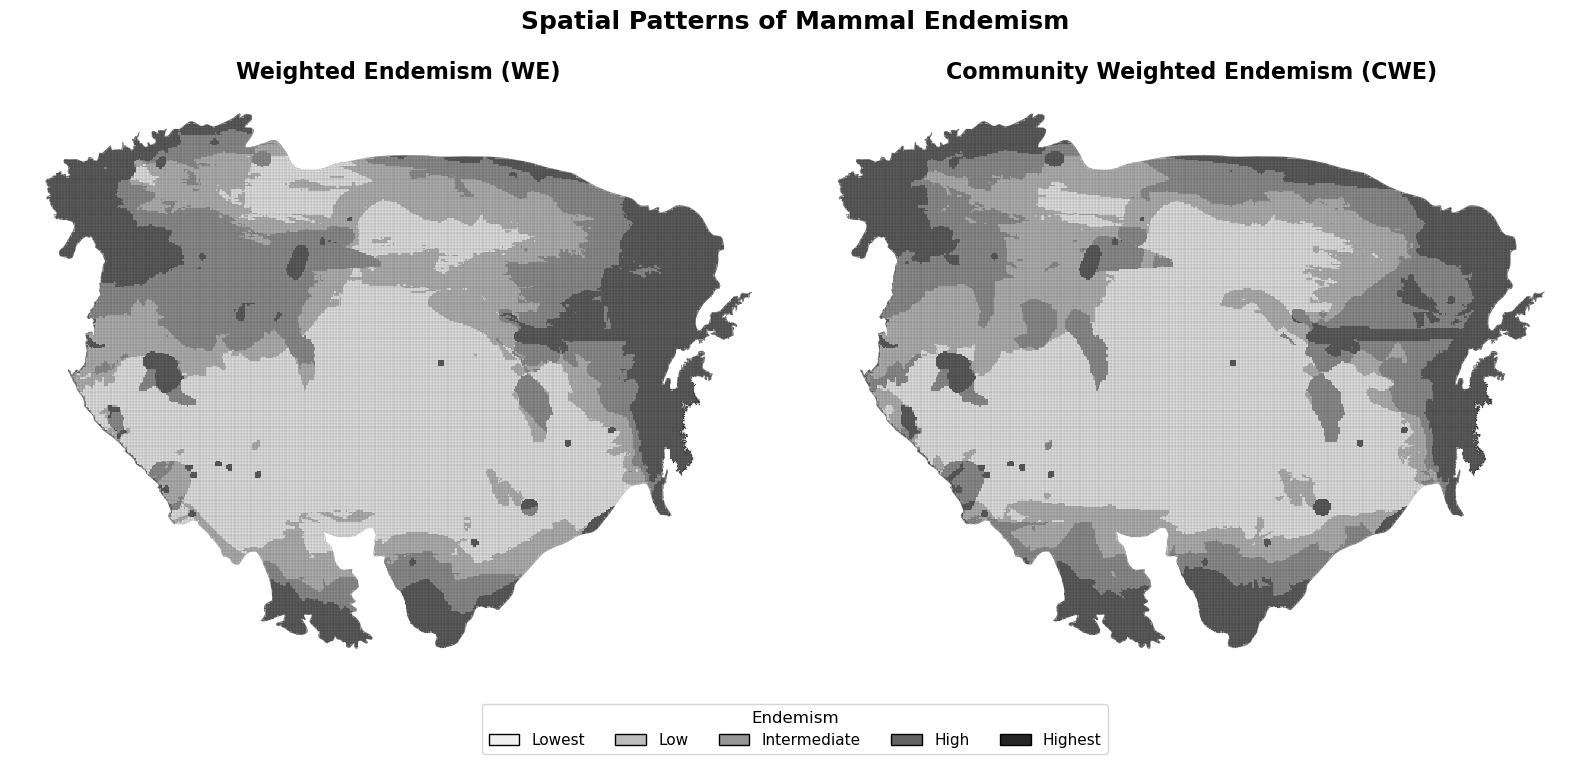

In [4]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# ---------------------------------------------------------
# 1. Define the five endemism categories
# ---------------------------------------------------------

labels = [
    "Lowest",
    "Low",
    "Intermediate",
    "High",
    "Highest"
]

# ---------------------------------------------------------
# 2. Classify WE and CWE using quintiles
# ---------------------------------------------------------

grid_mammal_biodiversity["WE_class"] = pd.qcut(
    grid_mammal_biodiversity["WE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

grid_mammal_biodiversity["CWE_class"] = pd.qcut(
    grid_mammal_biodiversity["CWE"],
    q=5,
    labels=labels,
    duplicates="drop"
)

# ---------------------------------------------------------
# 3. Convert categories to numeric values
# ---------------------------------------------------------

class_values = {
    "Lowest": 1,
    "Low": 2,
    "Intermediate": 3,
    "High": 4,
    "Highest": 5
}

grid_mammal_biodiversity["WE_class_num"] = grid_mammal_biodiversity["WE_class"].map(class_values)
grid_mammal_biodiversity["CWE_class_num"] = grid_mammal_biodiversity["CWE_class"].map(class_values)

# ---------------------------------------------------------
# 4. Create figure
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8)
)

# Five discrete colours
cmap = ListedColormap([
    "#f0f0f0",   # Lowest
    "#bdbdbd",   # Low
    "#969696",   # Intermediate
    "#636363",   # High
    "#252525"    # Highest
])

# ---------------------------------------------------------
# 5. Weighted Endemism
# ---------------------------------------------------------

grid_mammal_biodiversity.plot(
    column="WE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[0],
    vmin=1,
    vmax=5
)

axes[0].set_title(
    "Weighted Endemism (WE)",
    fontsize=16,
    fontweight="bold"
)

axes[0].axis("off")

# ---------------------------------------------------------
# 6. Corrected / Community Weighted Endemism
# ---------------------------------------------------------

grid_mammal_biodiversity.plot(
    column="CWE_class_num",
    cmap=cmap,
    linewidth=0.05,
    edgecolor="black",
    ax=axes[1],
    vmin=1,
    vmax=5
)

axes[1].set_title(
    "Community Weighted Endemism (CWE)",
    fontsize=16,
    fontweight="bold"
)

axes[1].axis("off")

# ---------------------------------------------------------
# 7. Common legend
# ---------------------------------------------------------

from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=cmap(0), edgecolor="black", label="Lowest"),
    Patch(facecolor=cmap(1), edgecolor="black", label="Low"),
    Patch(facecolor=cmap(2), edgecolor="black", label="Intermediate"),
    Patch(facecolor=cmap(3), edgecolor="black", label="High"),
    Patch(facecolor=cmap(4), edgecolor="black", label="Highest")
]

fig.legend(
    handles=legend_elements,
    title="Endemism",
    loc="lower center",
    ncol=5,
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02)
)

# ---------------------------------------------------------
# 8. Overall figure
# ---------------------------------------------------------

plt.suptitle(
    "Spatial Patterns of Mammal Endemism",
    fontsize=18,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.10, 1, 0.94])

# Save
plt.savefig(
    "mammal_endemism_WE_CWE.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()